# INSTITUTO Univeridad Autonoma del Estado de Mexico Centro Universitario UAEM Zumpango
**Asignatura:** Investigación de Operaciones
**Práctica 2:** Ruta Crítica (PERT/CPM)
**Integrantes:** 
-Alexis Yahir Alvarez Leon
- Ariadna Abigail Alanis Estrada, Jose Antonio Rodriguez Estudillo
**Fecha:** 15/11/26

## 1. Descripción y Planteamiento del Problema (Enfoque TI)
Una empresa de desarrollo de software necesita planificar la creación de una nueva aplicación web. El proyecto consta de **10 actividades** (desde el análisis de requerimientos hasta la capacitación al usuario). 

El objetivo es determinar la **duración total del proyecto** y encontrar la **ruta crítica** (la secuencia de actividades que no pueden retrasarse sin retrasar todo el proyecto), calculando los tiempos de inicio y fin (tempranos y tardíos), así como las holguras de cada actividad.

## 2. Definición de Datos
A continuación, definimos las 10 actividades, sus predecesoras y su duración en días.

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Definimos las actividades, predecesoras y duración (en días)
datos = [
    ('A', [], 3),       # Análisis de requerimientos
    ('B', ['A'], 4),    # Diseño UI/UX
    ('C', ['A'], 2),    # Configuración de Base de Datos
    ('D', ['C'], 6),    # Desarrollo Backend
    ('E', ['B'], 5),    # Desarrollo Frontend
    ('F', ['D', 'E'], 3), # Integración API
    ('G', ['F'], 4),    # Pruebas QA
    ('H', ['F'], 2),    # Auditoría de Seguridad
    ('I', ['G', 'H'], 1), # Despliegue en Servidor
    ('J', ['I'], 2)     # Capacitación al usuario
]

df = pd.DataFrame(datos, columns=['Actividad', 'Predecesoras', 'Duracion'])

# --- Cálculo de Tiempos Tempranos (Forward Pass) ---
ES = {} # Early Start
EF = {} # Early Finish

for index, row in df.iterrows():
    act = row['Actividad']
    if not row['Predecesoras']:
        ES[act] = 0
    else:
        ES[act] = max([EF[pred] for pred in row['Predecesoras']])
    EF[act] = ES[act] + row['Duracion']

df['ES'] = df['Actividad'].map(ES)
df['EF'] = df['Actividad'].map(EF)

# --- Cálculo de Tiempos Tardíos (Backward Pass) ---
LS = {} # Late Start
LF = {} # Late Finish

# La duración total del proyecto es el EF máximo
duracion_total = max(EF.values())

# Iteramos en reversa
for index, row in df.iloc[::-1].iterrows():
    act = row['Actividad']
    sucesoras = df[df['Predecesoras'].apply(lambda x: act in x)]['Actividad'].tolist()
    
    if not sucesoras:
        LF[act] = duracion_total
    else:
        LF[act] = min([LS[suc] for suc in sucesoras])
    LS[act] = LF[act] - row['Duracion']

df['LS'] = df['Actividad'].map(LS)
df['LF'] = df['Actividad'].map(LF)

# --- Cálculo de Holguras ---
df['Holgura'] = df['LS'] - df['ES']
df['Critica'] = df['Holgura'].apply(lambda x: 'Sí' if x == 0 else 'No')

print("--- TABLA DE TIEMPOS PERT/CPM ---")
display(df)

# Identificar la ruta crítica
ruta_critica = df[df['Holgura'] == 0]['Actividad'].tolist()
print(f"\n DURACIÓN TOTAL DEL PROYECTO: {duracion_total} días")
print(f" RUTA CRÍTICA: {' -> '.join(ruta_critica)}")

--- TABLA DE TIEMPOS PERT/CPM ---


,Actividad,Predecesoras,Duracion,ES,EF,LS,LF,Holgura,Critica
0,A,[],3,0,3,0,3,0,Sí
1,B,[A],4,3,7,3,7,0,Sí
2,C,[A],2,3,5,4,6,1,No
3,D,[C],6,5,11,6,12,1,No
4,E,[B],5,7,12,7,12,0,Sí
5,F,"[D, E]",3,12,15,12,15,0,Sí
6,G,[F],4,15,19,15,19,0,Sí
7,H,[F],2,15,17,17,19,2,No
8,I,"[G, H]",1,19,20,19,20,0,Sí
9,J,[I],2,20,22,20,22,0,Sí



 DURACIÓN TOTAL DEL PROYECTO: 22 días
 RUTA CRÍTICA: A -> B -> E -> F -> G -> I -> J


## 3. Visualización de la Red y Ruta Crítica
Para cumplir con el requisito de graficar el desarrollo, mostraremos el diagrama de red. Las actividades en la **ruta crítica se pintarán de color rojo y grueso**, mientras que las demás serán flechas grises.

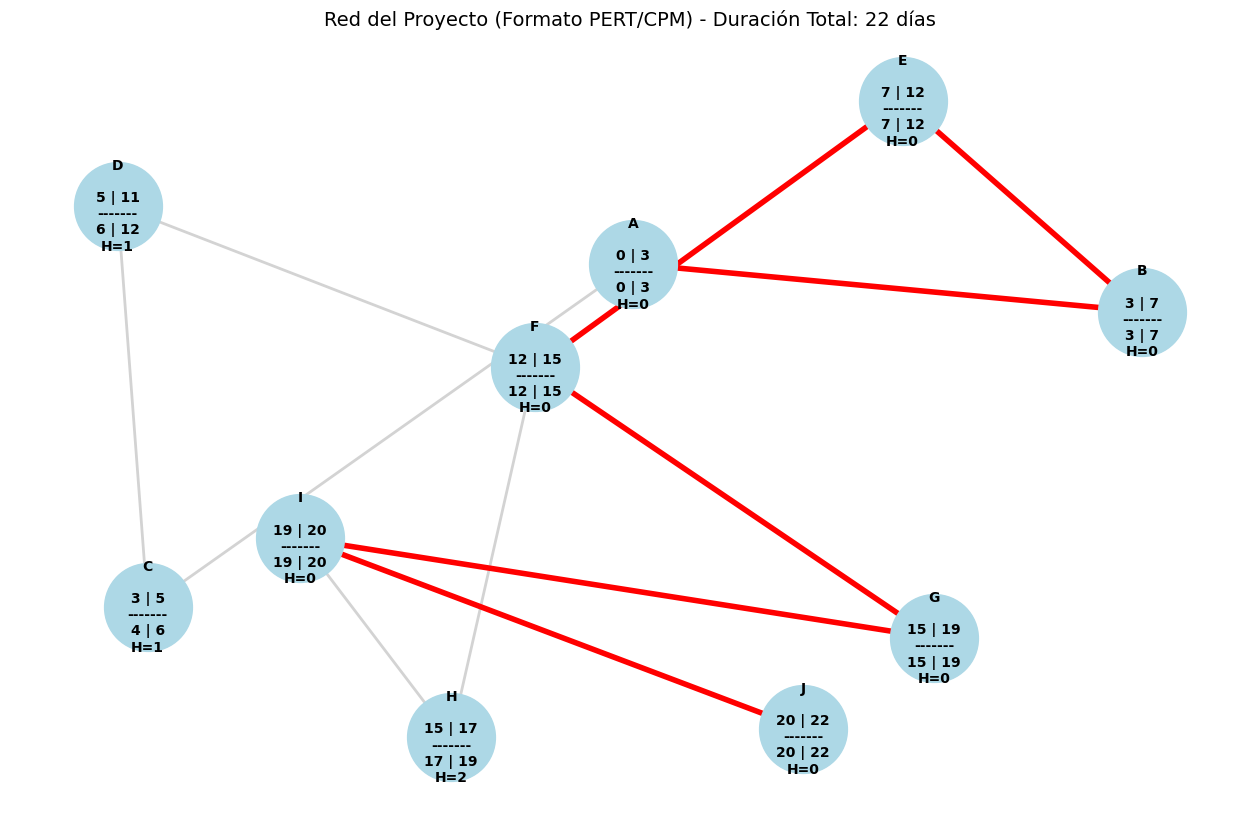

In [3]:
GG = nx.DiGraph()

# Agregar nodos y aristas al grafo
for index, row in df.iterrows():
    act = row['Actividad']
    G.add_node(act)
    for pred in row['Predecesoras']:
        G.add_edge(pred, act)

# Posiciones para el grafo
pos = nx.spring_layout(G, seed=42, k=1.5) # k=1.5 separa un poco más los nodos para que quepa el texto

plt.figure(figsize=(16, 10))

# Dibujar todos los nodos (más grandes para que quepa la información)
nx.draw_networkx_nodes(G, pos, node_size=4000, node_color='lightblue', node_shape='o')

# Dibujar aristas (todas primero en gris)
nx.draw_networkx_edges(G, pos, edge_color='lightgray', arrows=True, arrowsize=20, width=2)

# Resaltar la ruta crítica (flechas rojas)
aristas_criticas = []
for i in range(len(ruta_critica) - 1):
    aristas_criticas.append((ruta_critica[i], ruta_critica[i+1]))

nx.draw_networkx_edges(G, pos, edgelist=aristas_criticas, edge_color='red', width=4, arrows=True, arrowsize=25)

# --- CREAR EL FORMATO DE LA LIBRETA (Cruz con ES, EF, LS, LF y Holgura) ---
etiquetas_nodos = {}
for index, row in df.iterrows():
    act = row['Actividad']
    # Formato: 
    # Actividad
    #  ES | EF
    #  -------
    #  LS | LF
    #  H = Holgura
    etiquetas_nodos[act] = f"{act}\n\n{row['ES']} | {row['EF']}\n-------\n{row['LS']} | {row['LF']}\nH={row['Holgura']}"

# Dibujar las etiquetas con el nuevo formato
nx.draw_networkx_labels(G, pos, labels=etiquetas_nodos, font_size=10, font_weight='bold')

plt.title(f"Red del Proyecto (Formato PERT/CPM) - Duración Total: {duracion_total} días", fontsize=14)
plt.axis('off')
plt.show()

## 4. Interpretación de Resultados
El análisis PERT/CPM nos permitió identificar que la duración total del proyecto es de **22 días**. Las actividades que conforman la ruta crítica son **A -> B -> E -> F -> G -> I -> J**. 
Esto significa que si cualquiera de estas actividades sufre un retraso, todo el proyecto se retrasará. Por otro lado, observamos que las actividades C, D y H tienen una holgura de 1 o 2 días (H=1 y H=2), lo que significa que pueden retrasarse esos días sin afectar la fecha de entrega final.

## 5. Conclusiones
**Ariadna Abigail**:
La tabla de holguras es de mucha ayuda para organizar proyectos. Identificar las tareas que no se pueden retrasar permite planear mejor los tiempos de entrega del software.

**Jose Antonio**:
Hacer estos cálculos a mano es muy tardado. Usar Pandas para sacar los tiempos automáticamente facilita ver la ruta crítica y saber en qué actividades enfocar los recursos del equipo.



**Alexis:** Aprendí a implementar la lógica del PERT/CPM mediante programación, comprendiendo la importancia de calcular las holguras para la gestión eficiente de proyectos de software.